--- 1. Initial Dataset ---
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   target  
0       0  
1       0  
2       0  
3       0  
4       0  

--- 2. Dataset After Target Renaming and Synthetic Modifications ---
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                NaN               3.5                1.4               0.2   
1                NaN               3.0                1.4               0.2   
2                NaN               3.2                1.3               0.2   
3                NaN               3.1  

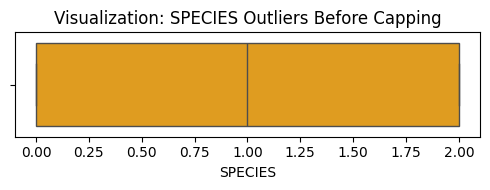


--- 4. Target Variable After Outlier Capping ---
   SPECIES
0        0
1        0
2        0
3        0
4        0


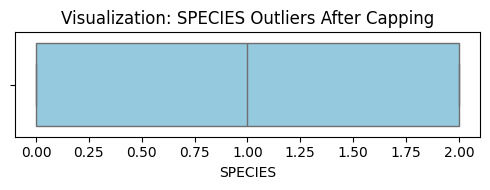


--- 5. Dataset After Categorical Encoding ---
   Origin_Exotic
0            0.0
1            1.0
2            0.0
3            1.0
4            0.0


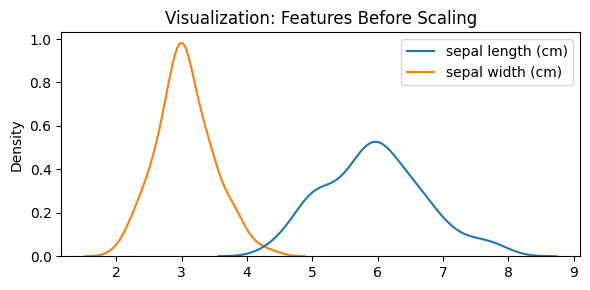


--- 6. Dataset After Feature Scaling ---
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                0.0          1.019004                1.4               0.2   
1                0.0         -0.131979                1.4               0.2   
2                0.0          0.328414                1.3               0.2   
3                0.0          0.098217                1.5               0.2   
4                0.0          1.249201                1.4               0.2   

    SPECIES  Origin_Exotic  
0 -1.224745            0.0  
1 -1.224745            1.0  
2 -1.224745            0.0  
3 -1.224745            1.0  
4 -1.224745            0.0  


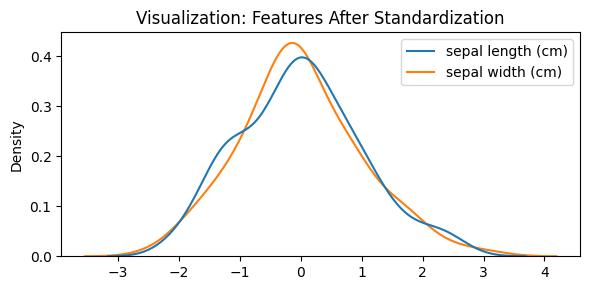

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
data = load_iris(as_frame=True)
df = data.frame
print("--- 1. Initial Dataset ---")
print(df.head())

df.rename(columns={"target": "SPECIES"}, inplace=True)
df.loc[0:15, "sepal length (cm)"] = np.nan  # Inject missing values
df["Origin"] = [
    "Domestic" if i % 2 == 0 else "Exotic" for i in range(len(df))
]
print("\n--- 2. Dataset After Target Renaming and Synthetic Modifications ---")
print(df.head())
imputer = SimpleImputer(strategy="mean")
df["sepal length (cm)"] = imputer.fit_transform(df[["sepal length (cm)"]])
print("\n--- 3. Dataset After Missing Value Imputation ---")
print(df[["sepal length (cm)"]].head())
plt.figure(figsize=(5, 2))
sns.boxplot(x=df["SPECIES"], color="orange")
plt.title("Visualization: SPECIES Outliers Before Capping")
plt.tight_layout()
plt.show()

# Interquartile Range (IQR) Capping
Q1, Q3 = df["SPECIES"].quantile(0.25), df["SPECIES"].quantile(0.75)
IQR = Q3 - Q1
df["SPECIES"] = np.clip(df["SPECIES"], Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)
print("\n--- 4. Target Variable After Outlier Capping ---")
print(df[["SPECIES"]].head())

plt.figure(figsize=(5, 2))
sns.boxplot(x=df["SPECIES"], color="skyblue")
plt.title("Visualization: SPECIES Outliers After Capping")
plt.tight_layout()
plt.show()

# 5. Task 3: Categorical Encoding & Display
encoder = OneHotEncoder(sparse_output=False, drop="first")
encoded_origin = encoder.fit_transform(df[["Origin"]])
df["Origin_Exotic"] = encoded_origin
df = df.drop(columns=["Origin"])

print("\n--- 5. Dataset After Categorical Encoding ---")
print(df[["Origin_Exotic"]].head())

# 6. Task 4: Feature Scaling & Display
plt.figure(figsize=(6, 3))
sns.kdeplot(data=df[["sepal length (cm)", "sepal width (cm)"]], common_norm=False)
plt.title("Visualization: Features Before Scaling")
plt.tight_layout()
plt.show()

# Standard Scaling on selected features and target
scaler = StandardScaler()
df[["sepal length (cm)", "sepal width (cm)", "SPECIES"]] = scaler.fit_transform(
    df[["sepal length (cm)", "sepal width (cm)", "SPECIES"]]
)

print("\n--- 6. Dataset After Feature Scaling ---")
print(df.head())

plt.figure(figsize=(6, 3))
sns.kdeplot(data=df[["sepal length (cm)", "sepal width (cm)"]], common_norm=False)
plt.title("Visualization: Features After Standardization")
plt.tight_layout()
plt.show()


--- 1. Initial Dataset ---
      RM  LSTAT  PTRATIO      MEDV
0  6.575   4.98     15.3  504000.0
1  6.421   9.14     17.8  453600.0
2  7.185   4.03     17.8  728700.0
3  6.998   2.94     18.7  701400.0
4  7.147   5.33     18.7  760200.0

--- 2. Dataset After Target Renaming and Synthetic Modifications ---
   RM  LSTAT  PTRATIO  TARGET_PRICE Property_Type
0 NaN   4.98     15.3      504000.0      Standard
1 NaN   9.14     17.8      453600.0       Premium
2 NaN   4.03     17.8      728700.0      Standard
3 NaN   2.94     18.7      701400.0       Premium
4 NaN   5.33     18.7      760200.0      Standard

--- 3. Dataset After Missing Value Imputation ---
      RM
0  6.185
1  6.185
2  6.185
3  6.185
4  6.185


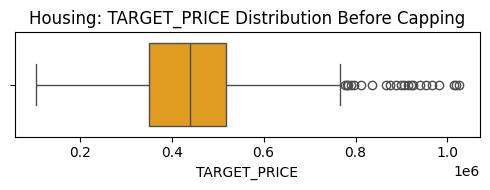


--- 4. Target Variable After Outlier Capping ---
   TARGET_PRICE
0      504000.0
1      453600.0
2      728700.0
3      701400.0
4      760200.0


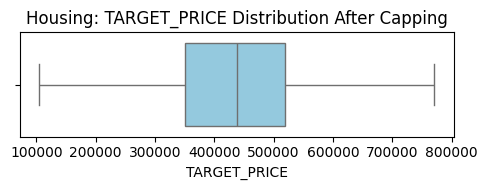


--- 5. Dataset After Categorical Encoding ---
   Property_Type_Premium
0                    1.0
1                    0.0
2                    1.0
3                    0.0
4                    1.0


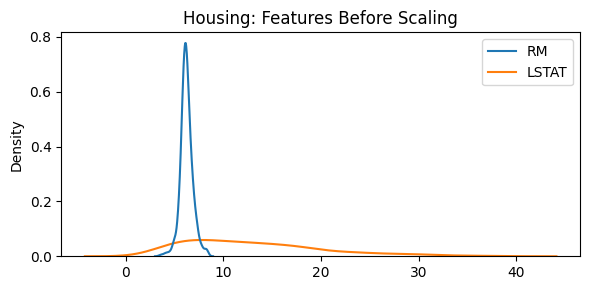


--- 6. Dataset After Feature Scaling ---
        RM     LSTAT  TARGET_PRICE
0 -0.08104 -1.125077      0.365758
1 -0.08104 -0.537070      0.031812
2 -0.08104 -1.259357      1.854596
3 -0.08104 -1.413427      1.673709
4 -0.08104 -1.075605      2.063312


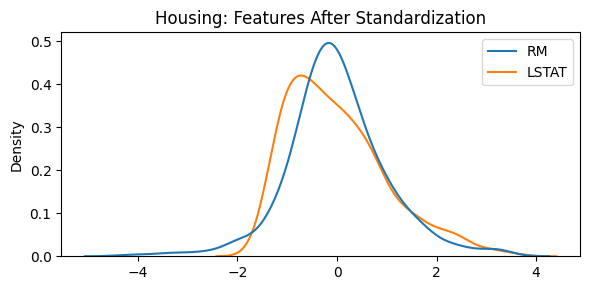

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Load the dataset from your local CSV file
df_housing = pd.read_csv("housing.csv")

print("--- 1. Initial Dataset ---")
print(df_housing.head())

# 2. Target adjustments and synthetic column generation
# Replace "median_house_value" with your CSV's actual target column name if it differs
target_col = (
    "median_house_value" if "median_house_value" in df_housing.columns else df_housing.columns[-1]
)
df_housing.rename(columns={target_col: "TARGET_PRICE"}, inplace=True)

# Select a feature to inject missing values (e.g., total_rooms or the first feature)
feature_to_impute = (
    "total_rooms" if "total_rooms" in df_housing.columns else df_housing.columns[0]
)
df_housing.loc[0:15, feature_to_impute] = np.nan  

# Add the synthetic categorical column matching your architecture
df_housing["Property_Type"] = [
    "Standard" if i % 2 == 0 else "Premium" for i in range(len(df_housing))
]

print("\n--- 2. Dataset After Target Renaming and Synthetic Modifications ---")
print(df_housing.head())

# 3. Missing value imputation
imputer = SimpleImputer(strategy="median")
df_housing[feature_to_impute] = imputer.fit_transform(df_housing[[feature_to_impute]])

print("\n--- 3. Dataset After Missing Value Imputation ---")
print(df_housing[[feature_to_impute]].head())

# 4. Outlier detection and Interquartile Range (IQR) Capping on the target
plt.figure(figsize=(5, 2))
sns.boxplot(x=df_housing["TARGET_PRICE"], color="orange")
plt.title("Housing: TARGET_PRICE Distribution Before Capping")
plt.tight_layout()
plt.show()

Q1, Q3 = df_housing["TARGET_PRICE"].quantile(0.25), df_housing["TARGET_PRICE"].quantile(0.75)
IQR = Q3 - Q1
df_housing["TARGET_PRICE"] = np.clip(
    df_housing["TARGET_PRICE"], Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
)

print("\n--- 4. Target Variable After Outlier Capping ---")
print(df_housing[["TARGET_PRICE"]].head())

plt.figure(figsize=(5, 2))
sns.boxplot(x=df_housing["TARGET_PRICE"], color="skyblue")
plt.title("Housing: TARGET_PRICE Distribution After Capping")
plt.tight_layout()
plt.show()

# 5. Categorical Encoding on the synthetic column
encoder = OneHotEncoder(sparse_output=False, drop="first")
encoded_type = encoder.fit_transform(df_housing[["Property_Type"]])
df_housing["Property_Type_Premium"] = encoded_type
df_housing = df_housing.drop(columns=["Property_Type"])

print("\n--- 5. Dataset After Categorical Encoding ---")
print(df_housing[["Property_Type_Premium"]].head())

# 6. Feature Scaling & Distribution Visualization
# Select another numerical feature to plot alongside the imputed feature (e.g., column index 1)
second_feature = df_housing.select_dtypes(include=[np.number]).columns[1]

plt.figure(figsize=(6, 3))
sns.kdeplot(data=df_housing[[feature_to_impute, second_feature]], common_norm=False)
plt.title("Housing: Features Before Scaling")
plt.tight_layout()
plt.show()

# Standard Scaling on selected features and the target variable
scaler = StandardScaler()
df_housing[[feature_to_impute, second_feature, "TARGET_PRICE"]] = scaler.fit_transform(
    df_housing[[feature_to_impute, second_feature, "TARGET_PRICE"]]
)

print("\n--- 6. Dataset After Feature Scaling ---")
print(df_housing[[feature_to_impute, second_feature, "TARGET_PRICE"]].head())

plt.figure(figsize=(6, 3))
sns.kdeplot(data=df_housing[[feature_to_impute, second_feature]], common_norm=False)
plt.title("Housing: Features After Standardization")
plt.tight_layout()
plt.show()
